In [1]:
# Setup: la cache dei modelli Hugging Face va su un disco a parte (HF_HOME, da cambiare sul proprio PC).
# Output: torch 2.5.1 e transformers 5.17 con GPU disponibile (RTX 2060): il sentiment gira su GPU (device=0).
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["HF_HOME"] = r"D:\aaaaaaaaaaaaa\Lav\strumenti\hf_cache" 
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import sys
import torch
import transformers

print(sys.executable)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("GPU disponibile:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

D:\aaaaaaaaaaaaa\Lav\strumenti\miniconda\envs\deeplearning\python.exe
torch: 2.5.1+cu121
transformers: 5.17.0
GPU disponibile: True
NVIDIA GeForce RTX 2060


In [2]:
# Si riparte dall'output del cleaning del progetto 1: qui servono le recensioni, poi ordini, clienti e prodotti per i collegamenti.
import pandas as pd
import pickle
from pathlib import Path

with open(Path("processed data/dfs_clean.pkl"), "rb") as f:
    dfs = pickle.load(f)

dfs.keys()   # devono esserci tutte e 9 le tabelle

dict_keys(['orders', 'items', 'payments', 'reviews', 'customers', 'products', 'sellers', 'geolocation', 'category_translation'])

## esplora e filtra

In [3]:
# Output: 99.224 recensioni in totale.
reviews = dfs["reviews"].copy()
print(len(reviews))
reviews.head()

99224


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


In [4]:
# Il voto è obbligatorio, il testo no: solo il 41,3% ha un messaggio (il titolo l'11,7%). Si lavora sul messaggio.
print("Con titolo (%):", round(reviews["review_comment_title"].notna().mean() * 100, 1))
print("Con messaggio (%):", round(reviews["review_comment_message"].notna().mean() * 100, 1))

Con titolo (%): 11.7
Con messaggio (%): 41.3


In [5]:
# Output: 40.977 recensioni con messaggio, mediana 53 caratteri e massimo 208: sono commenti brevi, nessun problema di lunghezza per il modello.
with_text = reviews[reviews["review_comment_message"].notna()].copy()
with_text["n_chars"] = with_text["review_comment_message"].str.len()

print(len(with_text))
print(with_text["n_chars"].describe())
print(with_text["n_chars"].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]))

40977
count    40977.000000
mean        68.637675
std         53.849207
min          1.000000
25%         28.000000
50%         53.000000
75%         95.000000
max        208.000000
Name: n_chars, dtype: float64
0.05      8.0
0.10     12.0
0.25     28.0
0.50     53.0
0.75     95.0
0.90    161.0
0.95    192.0
Name: n_chars, dtype: float64


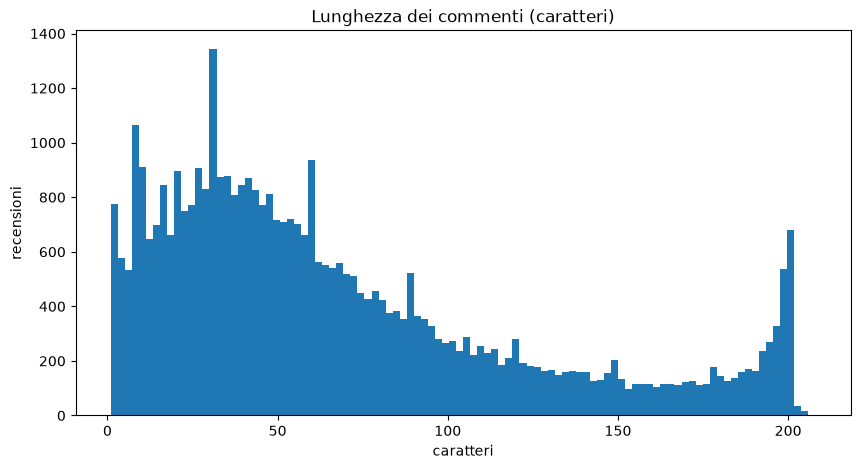

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(with_text["n_chars"], bins=100)
plt.title("Lunghezza dei commenti (caratteri)")
plt.xlabel("caratteri")
plt.ylabel("recensioni")
plt.show()

In [7]:
# Output: il 7,2% ha meno di 10 caratteri e il 26,5% meno di 30: serve per scegliere la soglia minima.
for t in [5, 10, 20, 30, 50,100]:
    share = (with_text["n_chars"] < t).mean() * 100
    print(f"sotto {t} caratteri: {share:.1f}%")

sotto 5 caratteri: 2.2%
sotto 10 caratteri: 7.2%
sotto 20 caratteri: 16.4%
sotto 30 caratteri: 26.5%
sotto 50 caratteri: 47.1%
sotto 100 caratteri: 76.7%


In [8]:
# Chi scrive un commento è più estremo: i voti 1 sono il 21,3% tra le recensioni con testo contro l'11,5% su tutte, i voti 5 il 50,2% contro il 57,8%.
# Implicazione: i risultati valgono per chi scrive, non per tutti i clienti.
all_dist = reviews["review_score"].value_counts(normalize=True).sort_index() * 100
text_dist = with_text["review_score"].value_counts(normalize=True).sort_index() * 100

comparison = pd.DataFrame({"tutte": all_dist, "con_testo": text_dist})
comparison["differenza_pp"] = comparison["con_testo"] - comparison["tutte"]
comparison["variazione_%"] = (comparison["con_testo"] / comparison["tutte"] - 1) * 100
comparison.round(1)

,tutte,con_testo,differenza_pp,variazione_%
review_score,,,,
1,11.5,21.3,9.8,85.4
2,3.2,5.2,2.1,64.8
3,8.2,8.7,0.4,5.3
4,19.3,14.6,-4.7,-24.4
5,57.8,50.2,-7.6,-13.2


In [9]:
# Lettura a mano dei commenti brevi: anche 5-30 caratteri portano significato ("Nao recebi o produto", "Veio com defeito").
pd.set_option("display.max_colwidth", 200)

short = with_text[with_text["n_chars"].between(5, 30)]
short[["review_score", "review_comment_message"]].sample(15, random_state=42)

,review_score,review_comment_message
25071,1,Nao recebi o produto
85941,5,Produto entregue no prazo
22415,5,Produto chegou rápido
98398,5,Atendimento muito eficaz
48311,5,Enrrega no prazo determinado
251,5,O produto chegou muito bem
54217,5,Adorei!!
43957,5,otimo
90066,4,excelente produto
24476,5,otimo


In [10]:
# Output: 3.199 commenti sotto i 10 caratteri, quasi tutti elogi brevi ("muito bom", "bom", "recomendo"): informativi, non rumore.
# Toglie spazi e a-capo a inizio/fine: un messaggio fatto solo di spazi non è testo vero
with_text["review_comment_message"] = with_text["review_comment_message"].str.strip()
with_text["n_chars"] = with_text["review_comment_message"].str.len()

# Quali sono i commenti più frequenti sotto i 10 caratteri
very_short = with_text[with_text["n_chars"] < 10]
print(len(very_short))
very_short["review_comment_message"].str.lower().value_counts().head(25)

3199


review_comment_message
muito bom    472
bom          342
recomendo    234
otimo        227
ótimo        197
excelente    158
ok           149
tudo ok       93
boa           91
gostei        65
.             52
otima         45
adorei        42
perfeito      42
nota 10       39
ótima         36
              27
muito boa     26
amei          25
top           24
tudo ok.      22
10            19
obrigado      19
parabéns      18
bom.          13
Name: count, dtype: int64

In [11]:
# Soglia minima di 3 caratteri: escluso solo ciò che è troppo corto per contenere un'opinione. Output: 321 commenti tolti, restano 40.656.
threshold = 3

filtered = with_text[with_text["n_chars"] >= threshold].copy()
print(len(with_text), len(filtered), len(with_text) - len(filtered))

40977 40656 321


In [12]:
# Output: 40.377 ordini con 1 recensione, 138 con 2 e 1 con 3: prima di ogni join con gli ordini si aggrega per ordine.
print(filtered["order_id"].value_counts().value_counts())

count
1    40377
2      138
3        1
Name: count, dtype: int64


## preprocessing

In [13]:
# Controllo dei difetti del testo. Output: 2.710 commenti con a capo, 2 con link, nessun carattere rovinato dalla codifica.
# 49 commenti non hanno lettere ("...", "100%", emoji): restano nel sentiment ma non avranno parole nell'analisi dei temi.
msg = filtered["review_comment_message"]

print("con a capo:", msg.str.contains(r"[\r\n]").sum())
print("con spazi multipli:", msg.str.contains(r"\s{2,}").sum())
print("con link:", msg.str.contains(r"http|www\.", case=False).sum())
print("con � (carattere perso):", msg.str.contains("�").sum())
print("con Ã + simbolo (codifica rovinata, es. Ã£):", msg.str.contains("Ã[\u00a0-\u00bf]").sum())

has_letter = msg.str.contains(r"[^\W\d_]")   # True se c'è almeno una lettera
print("senza nessuna lettera:", (~has_letter).sum())
msg[~has_letter].value_counts().head(15)

con a capo: 2710
con spazi multipli: 2711
con link: 2
con � (carattere perso): 0
con Ã + simbolo (codifica rovinata, es. Ã£): 0
senza nessuna lettera: 49


review_comment_message
...                                                                                           11
100%                                                                                           5
.....                                                                                          3
....                                                                                           3
.........                                                                                      2
👍👍👍                                                                                            2
*******************                                                                            1
. .                                                                                            1
.... ...... ..........                                                                         1
😆😆😆😆😆😆                                                                                         1
///////

In [14]:
# Pulizia leggera di proposito: si normalizzano solo gli spazi. Minuscole, accenti, stopword e negazioni restano, perché per i transformer portano significato.
filtered["text_clean"] = (
    filtered["review_comment_message"]
    .str.replace(r"\s+", " ", regex=True)   # a capo, tab e spazi multipli diventano uno spazio
    .str.strip()
)

In [15]:
# Output: modificate 2.711 righe (solo spazi e a capo), nessuna scende sotto la soglia.
changed = filtered["review_comment_message"] != filtered["text_clean"]
print("righe prima/dopo:", len(filtered), filtered["text_clean"].notna().sum())
print("righe modificate:", changed.sum())
print("sotto soglia dopo la pulizia:", (filtered["text_clean"].str.len() < threshold).sum())

filtered.loc[changed, ["review_comment_message", "text_clean"]].head(5)

righe prima/dopo: 40656 40656
righe modificate: 2711
sotto soglia dopo la pulizia: 0


,review_comment_message,text_clean
27,"A compra foi realizada facilmente.\r\nA entrega foi efetuada muito antes do prazo dado.\r\nO produto já começou a ser usado e até o presente,\r\nsem problemas.","A compra foi realizada facilmente. A entrega foi efetuada muito antes do prazo dado. O produto já começou a ser usado e até o presente, sem problemas."
51,recebi somente 1 controle Midea Split ESTILO.\r\nFaltou Controle Remoto para Ar Condicionado Consul,recebi somente 1 controle Midea Split ESTILO. Faltou Controle Remoto para Ar Condicionado Consul
61,Ocorreu tudo como contratado sendo a entrega realizada antes do prazo \r\n Estou satisfeita,Ocorreu tudo como contratado sendo a entrega realizada antes do prazo Estou satisfeita
103,estao de parabens... sempre chega com muiiita antecedencia..\r\n\r\nMuito obrigada....,estao de parabens... sempre chega com muiiita antecedencia.. Muito obrigada....
115,"Este foi o pedido\r\nBalde Com 128 Peças - Blocos De Montar 2 un - R$ 25,00 cada (NÃO FOI ENTREGUE)\r\nVendido e entregue targaryen\r\nTapete de Eva Nº Letras 36 Peças Crianças 1 un - R$ 35,90 (ES...","Este foi o pedido Balde Com 128 Peças - Blocos De Montar 2 un - R$ 25,00 cada (NÃO FOI ENTREGUE) Vendido e entregue targaryen Tapete de Eva Nº Letras 36 Peças Crianças 1 un - R$ 35,90 (ESTE FOI EN..."


In [16]:
# Salva il testo pulito: da qui in poi si lavora solo su questo file.
cols = ["review_id", "order_id", "review_score", "text_clean"]
filtered[cols].to_pickle(Path("processed data/reviews_text.pkl"))

## modello

In [17]:
import pandas as pd
from pathlib import Path

reviews_text = pd.read_pickle(Path("processed data/reviews_text.pkl"))
print(len(reviews_text))   # deve essere 40656

40656


In [18]:
# Campione stratificato per voto (60 per voto, 300 in tutto, seed fisso) per confrontare i modelli.
# Le stelle sono una verità approssimata, quindi dopo le metriche si leggono a mano i disaccordi.
sample = (
    reviews_text.groupby("review_score", group_keys=False)
    .sample(n=60, random_state=42)
    .reset_index(drop=True)
)
print(sample["review_score"].value_counts().sort_index())

review_score
1    60
2    60
3    60
4    60
5    60
Name: count, dtype: int64


In [19]:
# Le stelle diventano classi (1-2 negativo, 3 neutro, 4-5 positivo) e si confronta la predizione con precision, recall e F1.
# Il voto 3 non è un vero neutro: nel confronto finale si guarda anche senza.
import torch
from transformers import pipeline
from IPython.display import display
from sklearn.metrics import classification_report

star_class = sample["review_score"].map(
    {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
)

def test_model(model_name, col, label_map=None):
    clf = pipeline("text-classification", model=model_name, device=0,
                   model_kwargs={"use_safetensors": True})
    out = clf(list(sample["text_clean"]), batch_size=16, truncation=True, max_length=256)
    del clf
    torch.cuda.empty_cache()

    res = pd.DataFrame(out)
    labels = res["label"].str.lower()
    if label_map:                                    # chiavi in minuscolo, es. "label_0"
        labels = labels.map(label_map).fillna(labels)
    sample[f"pred_{col}"] = labels
    sample[f"conf_{col}"] = res["score"]

    print(sample[f"pred_{col}"].value_counts(), "\n")
    print("Distribuzione della predizione per voto (% di riga):")
    display(pd.crosstab(sample["review_score"], sample[f"pred_{col}"], normalize="index").mul(100).round(1))
    print(classification_report(star_class, sample[f"pred_{col}"], zero_division=0))

In [20]:
# Modello A (3 classi, addestrato su tweet). Output: accuracy 0,59; manda il 30-40% dei voti 1-2 in "neutral" (F1 sul neutro 0,27).
model_a = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
test_model(model_a, "a")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

pred_a
negative    115
positive     97
neutral      88
Name: count, dtype: int64 

Distribuzione della predizione per voto (% di riga):


pred_a,negative,neutral,positive
review_score,,,
1,68.3,30.0,1.7
2,58.3,40.0,1.7
3,45.0,33.3,21.7
4,18.3,30.0,51.7
5,1.7,13.3,85.0


              precision    recall  f1-score   support

    negative       0.66      0.63      0.65       120
     neutral       0.23      0.33      0.27        60
    positive       0.85      0.68      0.76       120

    accuracy                           0.59       300
   macro avg       0.58      0.55      0.56       300
weighted avg       0.65      0.59      0.62       300



In [21]:
# Disaccordi forti di A (negativo contro positivo): solo 14 su 300, 12 sono voti 4 letti come negativi.
pd.set_option("display.max_colwidth", 250)

bad = sample[
    ((star_class == "negative") & (sample["pred_a"] == "positive"))
    | ((star_class == "positive") & (sample["pred_a"] == "negative"))
]
print(len(bad))
bad[["review_score", "pred_a", "conf_a", "text_clean"]].head(20)

14


,review_score,pred_a,conf_a,text_clean
18,1,positive,0.646532,O cheiro do produto e muito forte! Mas pelo preço não tenho do que reclamar!
68,2,positive,0.521930,"Gostei do design do relógio porém veio sem a caixa e jogado na caixa do correio, na minha opinião cada detalhe é importante principalmente com a fidelização do cliente...."
180,4,negative,0.741946,Não correspondia com a imagem. Deviam colocar o tamanho na descrição
184,4,negative,0.557472,os pés poderiam ser melhor acabados
188,4,negative,0.688624,"O produto é lindo a entrega foi super rápida, porém me entregaram errado...comprei um de 2,5 L e me entregaram um de 1,5 L, estou aguardando retorno do parceiro."
196,4,negative,0.563792,Ótimo produto. Só os correios q como sempre fez lambança e demorou um pouco mais pra chegar.
201,4,negative,0.489884,"É um kit bom de qualidade, no entanto o pincel de esfumar é muito magrinho."
220,4,negative,0.497221,"A entrega foi rápida, mas temos que melhorar no rastreamento, pois a gente quase não consegui rastrear."
226,4,negative,0.411991,Otimo produto porem caro demais !!!
228,4,negative,0.785201,Demorou demais pra chegar


In [22]:
# Modello B (BERT portoghese): LABEL_2 non compare mai nel campione, quindi di fatto negativo/positivo. Il report totale (accuracy 0,69) non è confrontabile con A.
# Output: sul voto 3 si divide (57% negativo, 43% positivo): spinge verso un lato. Recall 0,83 sui negativi e 0,89 sui positivi.
model_b = "lipaoMai/BERT-sentiment-analysis-portuguese"
map_b = {"label_0": "negative", "label_1": "positive", "label_2": "label_2"}
test_model(model_b, "b", label_map=map_b)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

pred_b
positive    153
negative    147
Name: count, dtype: int64 

Distribuzione della predizione per voto (% di riga):


pred_b,negative,positive
review_score,,
1,80.0,20.0
2,86.7,13.3
3,56.7,43.3
4,16.7,83.3
5,5.0,95.0


              precision    recall  f1-score   support

    negative       0.68      0.83      0.75       120
     neutral       0.00      0.00      0.00        60
    positive       0.70      0.89      0.78       120

    accuracy                           0.69       300
   macro avg       0.46      0.58      0.51       300
weighted avg       0.55      0.69      0.61       300



In [23]:
# Confronto equo: solo voti diversi da 3. Output: B accuracy 0,86 (F1 0,86); A manda 42 negativi su 120 in "neutral" e ne riconosce 76, B ne riconosce 100.
polar = sample["review_score"] != 3
for col in ["a", "b"]:
    print("Modello", col.upper())
    display(pd.crosstab(star_class[polar], sample.loc[polar, f"pred_{col}"], margins=True))

print(classification_report(star_class[polar], sample.loc[polar, "pred_b"], zero_division=0))

Modello A


pred_a,negative,neutral,positive,All
review_score,,,,
negative,76,42,2,120
positive,12,26,82,120
All,88,68,84,240


Modello B


pred_b,negative,positive,All
review_score,,,
negative,100,20,120
positive,13,107,120
All,113,127,240


              precision    recall  f1-score   support

    negative       0.88      0.83      0.86       120
    positive       0.84      0.89      0.87       120

    accuracy                           0.86       240
   macro avg       0.86      0.86      0.86       240
weighted avg       0.86      0.86      0.86       240



In [24]:
# Disaccordi di B: 33 su 240, in maggioranza voti 1-2 letti come positivi. Sono segnalazioni di un problema senza parole negative
# ("Cadê a minha torneira?", "Está em atraso!") o scritte con tono cortese.
bad_b = sample[
    ((star_class == "negative") & (sample["pred_b"] == "positive"))
    | ((star_class == "positive") & (sample["pred_b"] == "negative"))
]
print(len(bad_b))
bad_b[["review_score", "pred_b", "conf_b", "text_clean"]].head(20)

33


,review_score,pred_b,conf_b,text_clean
1,1,positive,0.964745,Falta de respeito com o cliente
10,1,positive,0.844499,"Boa tarde, Os produtos foram entregues ontem em pleno domingo, no qual nao haviam pessoas responsáveis pelo recebimento de mercadorias, o qual ficaram faltando 4 cadeiras."
18,1,positive,0.992149,O cheiro do produto e muito forte! Mas pelo preço não tenho do que reclamar!
23,1,positive,0.571709,"A embalagem bem diferente do anunciado,sou acostumada a comprar esse produto nunca tinha recebido com essa embalagem."
33,1,positive,0.532855,até o presente momento não foi entregue!
41,1,positive,0.715380,Cadê a minha torneira?
43,1,positive,0.899368,Foi vendido um produto como sendo original e veio uma imitação.
46,1,positive,0.718511,Faltou a capa Case com a película só entregaram o cartão de memória.
47,1,positive,0.929290,Está em atraso!
50,1,positive,0.894279,"As pessoas não conseguem contato. Inclusive estou indo atrás dos meus direitos como consumidor e por estar me sentindo lesado. A pessoa a qual comprei a mochila, está levando com saco plástico."


In [25]:
# Test sul caso più frequente: negativi che parlano di consegna (78 su 120). Output: A ne riconosce 49 (29 finiscono in neutral), B ne riconosce 66.
delivery = sample["text_clean"].str.contains(r"entreg|prazo|atras|demor|receb|chegou", case=False, regex=True)
neg = star_class == "negative"
print("negativi con parole di consegna:", (delivery & neg).sum(), "su", neg.sum())

for col in ["a", "b"]:
    print("Modello", col.upper())
    display(sample.loc[delivery & neg, f"pred_{col}"].value_counts())

negativi con parole di consegna: 78 su 120
Modello A


pred_a
negative    49
neutral     29
Name: count, dtype: int64

Modello B


pred_b
negative    66
positive    12
Name: count, dtype: int64

In [26]:
# Output: B dà solo negative/positive. Unire i due modelli (OR) recupera pochi negativi (106 su 120 contro 100) e aggiunge falsi allarmi (21 positivi contro 13):
# si tiene B da solo. Restano 14 negativi su 120 (circa 12%) che sfuggono a entrambi: limite da dichiarare.
print(sample["pred_b"].value_counts())   # devono comparire solo negative e positive

polar = sample["review_score"] != 3
neg_or = (sample["pred_a"] == "negative") | (sample["pred_b"] == "negative")
pd.crosstab(star_class[polar], neg_or[polar], margins=True)

pred_b
positive    153
negative    147
Name: count, dtype: int64


col_0,False,True,All
review_score,,,
negative,14,106,120
positive,99,21,120
All,113,127,240


## sentiment su tutto il sottoinsieme

In [27]:
# Modello scelto: B su tutte le 40.656 recensioni. top_k=None restituisce le probabilità di tutte e tre le etichette, non solo la massima.
# max_length=256 token copre i commenti (massimo 208 caratteri).
import time
import numpy as np
import torch
from transformers import pipeline

clf = pipeline(
    "text-classification",
    model="lipaoMai/BERT-sentiment-analysis-portuguese",
    device=0,
    model_kwargs={"use_safetensors": True},
)

texts = list(reviews_text["text_clean"])
print(len(texts))
print(clf(texts[:3], top_k=None, truncation=True, max_length=256))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

40656
[[{'label': 'LABEL_1', 'score': 0.9905348420143127}, {'label': 'LABEL_0', 'score': 0.009444090537726879}, {'label': 'LABEL_2', 'score': 2.102277176163625e-05}], [{'label': 'LABEL_1', 'score': 0.9933870434761047}, {'label': 'LABEL_0', 'score': 0.006577343214303255}, {'label': 'LABEL_2', 'score': 3.560698314686306e-05}], [{'label': 'LABEL_1', 'score': 0.7970724701881409}, {'label': 'LABEL_0', 'score': 0.20285248756408691}, {'label': 'LABEL_2', 'score': 7.502369408030063e-05}]]


In [28]:
# Output: 2 secondi per 1.000 testi, quindi circa 100 secondi per tutte le recensioni.
t0 = time.time()
_ = clf(texts[:1000], batch_size=32, top_k=None, truncation=True, max_length=256)
print(round(time.time() - t0, 1), "secondi per 1000 testi")

2.0 secondi per 1000 testi


In [29]:
# Output: 27.893 positive, 12.734 negative e 29 con LABEL_2. LABEL_2 non è un neutro: ha probabilità quasi sempre vicina a 0 (mediana 0,00006).
out = clf(texts, batch_size=32, top_k=None, truncation=True, max_length=256)

# una riga per recensione, una colonna per etichetta (LABEL_0, LABEL_1, LABEL_2)
p = pd.DataFrame([{d["label"].upper(): d["score"] for d in o} for o in out])

# .values: reviews_text ha l'indice originale (non 0..n), così le righe restano allineate per posizione
reviews_text["p_negative"] = p["LABEL_0"].values
reviews_text["p_positive"] = p["LABEL_1"].values
reviews_text["p_label2"] = p["LABEL_2"].values
reviews_text["sentiment"] = (
    p.idxmax(axis=1)   # classe con probabilità più alta, come nel test sul campione
    .map({"LABEL_0": "negative", "LABEL_1": "positive", "LABEL_2": "label_2"})
    .values
)

print(reviews_text["sentiment"].value_counts())
print(reviews_text["p_label2"].describe())

sentiment
positive    27893
negative    12734
label_2        29
Name: count, dtype: int64
count    40656.000000
mean         0.000997
std          0.024577
min          0.000017
25%          0.000040
50%          0.000060
75%          0.000288
max          0.992918
Name: p_label2, dtype: float64


In [30]:
# Output: 68,6% positive e 31,3% negative. La quota di negativi scende con le stelle (86,8% → 3,7%) e così la probabilità media di negativo (0,84 → 0,05):
# il modello segue il voto, ma il voto 3 si divide quasi a metà (52% negativo, 48% positivo).
print(reviews_text["sentiment"].value_counts(normalize=True).mul(100).round(1))
print(pd.crosstab(reviews_text["review_score"], reviews_text["sentiment"], normalize="index").mul(100).round(1))
print(reviews_text.groupby("review_score")["p_negative"].mean().round(2))

reviews_text.to_pickle(Path("processed data/reviews_sentiment.pkl"))

sentiment
positive    68.6
negative    31.3
label_2      0.1
Name: proportion, dtype: float64
sentiment     label_2  negative  positive
review_score                             
1                 0.0      86.8      13.2
2                 0.1      75.3      24.6
3                 0.0      52.0      47.9
4                 0.2      16.2      83.7
5                 0.1       3.7      96.2
review_score
1    0.84
2    0.73
3    0.51
4    0.17
5    0.05
Name: p_negative, dtype: float64


In [31]:
# Le 29 recensioni con LABEL_2 (0,07%) hanno voti sparsi da 1 a 5: non sono una classe affidabile e si escludono da ogni analisi successiva (sentiment_ok).
l2 = reviews_text[reviews_text["sentiment"] == "label_2"]
print("label_2:", len(l2), f"({len(l2)/len(reviews_text)*100:.2f}%)")
print(l2["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1))

for _, r in l2.sample(min(15, len(l2)), random_state=42).iterrows():
    print(r["review_score"], round(r["p_label2"], 2), "|", r["text_clean"])

print(Path("processed data/reviews_sentiment.pkl").exists())

label_2: 29 (0.07%)
review_score
1    13.8
2    10.3
3     3.4
4    31.0
5    41.4
Name: proportion, dtype: float64
4 0.94 | Recebi o produto correto e antes mesmo da data limite do prazo de entrega! O único porém foi o estado de conservação: a caixa chegou um pouco amassada o que talvez tenha contribuído para um dano...
5 0.99 | produto chegou em bom estado, e a qualidade bem superior a algumas que jah comprei , percebece que e bem mais resistente
1 0.98 | Não consegui resposta de ninguém para saber sobre o estado da minha encomenda ou informar motivo do atraso.
5 0.99 | Comprei aqui em são Paulo, para presentear em outro estado... Fiquei super preocupada porq a minha irmã vai ganhar bb agora no fim do mês, e a loja me deu o prazo ate dia 03/03 mesmo assim arrisque
4 0.56 | Recebi os produtos no prazo em ótimo estado.
5 0.99 | Apesar pagar frete e ainda ter que ir aos Correios buscar a encomenda, o produto veio em bom estado e era exatamente o que eu precisava
2 0.69 | A caixa veio se

## keyword topic modelling

In [32]:
# Nucleo per keyword e temi: solo recensioni dove stelle e modello concordano (voto ≤ 2 e negativo, voto ≥ 4 e positivo),
# così i temi non dipendono dagli errori del modello. Output: 9.187 negativi e 24.522 positivi.
reviews_text["sentiment_ok"] = reviews_text["sentiment"] != "label_2"

neg_core = reviews_text[(reviews_text["review_score"] <= 2) & (reviews_text["sentiment"] == "negative")]
pos_core = reviews_text[(reviews_text["review_score"] >= 4) & (reviews_text["sentiment"] == "positive")]
print("negativi core:", len(neg_core), "| positivi core:", len(pos_core))

reviews_text.to_pickle(Path("processed data/reviews_sentiment.pkl"))

negativi core: 9187 | positivi core: 24522


In [33]:
# Le stopword portoghesi di NLTK (207) includono "não", "nem", "sem": nei negativi portano il significato, quindi nel passo dopo si tengono.
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords

sw = set(stopwords.words("portuguese"))
print(len(sw))
print([w for w in ["não", "nao", "nem", "sem", "muito", "mais", "bom", "produto", "chegou"] if w in sw])

207
['não', 'nem', 'sem', 'muito', 'mais']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\richi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [34]:
# Seconda versione del testo per keyword e temi (text_topic): minuscolo, senza accenti, senza stopword tranne le negazioni. 56 righe restano vuote.
# Output: nei negativi dominano "nao", "recebi", "ainda", "entregue"; nei positivi "prazo", "antes", "recomendo".
# Compaiono anche parole generiche (produto, loja, compra) e "lannister": vanno tolte.
import re, unicodedata
from collections import Counter

def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

keep = {"não", "nem", "sem"}
sw_clean = {strip_accents(w) for w in sw if w not in keep}

def make_topic_text(t):
    t = strip_accents(t.lower())
    words = re.findall(r"[a-z]{2,}", t)
    return " ".join(w for w in words if w not in sw_clean)

reviews_text["text_topic"] = reviews_text["text_clean"].map(make_topic_text)
print("righe vuote dopo la pulizia:", (reviews_text["text_topic"] == "").sum())

for name, idx in [("NEGATIVI", neg_core.index), ("POSITIVI", pos_core.index)]:
    c = Counter(" ".join(reviews_text.loc[idx, "text_topic"]).split())
    print(name, c.most_common(30))

righe vuote dopo la pulizia: 56
NEGATIVI [('nao', 8077), ('produto', 5650), ('recebi', 3202), ('comprei', 1763), ('veio', 1424), ('ainda', 1256), ('entregue', 1169), ('entrega', 1105), ('chegou', 1027), ('compra', 837), ('pedido', 746), ('dia', 695), ('loja', 689), ('agora', 632), ('prazo', 595), ('nem', 502), ('lannister', 494), ('pois', 488), ('apenas', 483), ('site', 479), ('quero', 477), ('nada', 476), ('produtos', 455), ('contato', 452), ('dois', 451), ('sem', 450), ('porem', 422), ('outro', 414), ('pra', 377), ('dias', 377)]
POSITIVI [('produto', 9700), ('prazo', 6963), ('antes', 5159), ('entrega', 4409), ('bom', 3942), ('recomendo', 3860), ('chegou', 3792), ('bem', 2575), ('otimo', 2370), ('qualidade', 2098), ('entregue', 2020), ('tudo', 1983), ('excelente', 1766), ('super', 1611), ('rapida', 1575), ('gostei', 1414), ('loja', 1363), ('nao', 1190), ('dentro', 1155), ('otima', 1100), ('rapido', 1097), ('recebi', 1092), ('parabens', 1067), ('compra', 1029), ('boa', 979), ('perfeito

In [35]:
# "lannister" (1.208 recensioni, 640 positive e 568 negative) non è sentiment: è il nome anonimizzato di un negozio. Si toglie insieme alle parole generiche.
# Output: le parole che separano i gruppi sono "nao" (66,3% dei negativi contro 4,4% dei positivi) e "recebi" (32,1% contro 4,4%);
# "prazo" e "recomendo" stanno nei positivi.
lan = reviews_text[reviews_text["text_topic"].str.contains("lannister")]
print("recensioni con lannister:", len(lan))
print(lan["sentiment"].value_counts())
for t in lan["text_clean"].sample(8, random_state=42):
    print("-", t)

neg_t = reviews_text.loc[neg_core.index, "text_topic"]
pos_t = reviews_text.loc[pos_core.index, "text_topic"]
for w in ["nao", "prazo", "entrega", "recebi", "chegou", "recomendo", "qualidade"]:
    n = neg_t.str.contains(rf"\b{w}\b").mean() * 100
    p = pos_t.str.contains(rf"\b{w}\b").mean() * 100
    print(f"{w:10s} neg {n:5.1f}%  pos {p:5.1f}%")

recensioni con lannister: 1208
sentiment
positive    640
negative    568
Name: count, dtype: int64
- O pedido veio errado. Está a maior burocracia p trocar. Eles jogam p lannister' e a lannister' diz que eu tenho que resolver com eles. -.-'
- Sempre gostei das lannister
- Fui enganado. ficou faltando um produto e me entregaram como se tivesse o pedido completo. Compro na lannister..com há muitos anos e nunca tive este tipo de problema antes
- Apesar de ter sido entregue no prazo levou dez dias para emitirem a nota fiscal sendo que já recebi vários produtos que comprei na lannister em três dias melhorem isso aí!
- Gostaria de sabe o que aconteceu com meu produto estou desepicionada com as lojas lannister.Preciso urgente de uma posição da loja pois a primeira prestação no cartão está sendo paga.
- Nota 10 para lannister e targaryen!!!!
- O produto chegou antes do que imaginei. Até me surpreendi. A lannister é ótima!
- Estou esperando até agora a entrega do produto, a nota fiscal não foi 

In [36]:
# Stopword di dominio e TF-IDF con bigrammi sul nucleo (min_df=20, max_df=0.5). Output: matrice 33.709 × 1.747.
# I negativi sono "nao recebi", "ainda nao", "nao entregue", "nao chegou"; i positivi "antes prazo", "recomendo", "entrega rapida": le negazioni fanno la differenza.
domain_sw = {"produto", "produtos", "loja", "compra", "comprei", "pra", "pois",
             "apenas", "porem", "outro", "lannister", "targaryen"}
sw_final = sw_clean | domain_sw

def make_topic_text2(t):
    t = strip_accents(t.lower())
    words = re.findall(r"[a-z]{2,}", t)
    return " ".join(w for w in words if w not in sw_final)

reviews_text["text_topic"] = reviews_text["text_clean"].map(make_topic_text2)

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

core = reviews_text.loc[list(neg_core.index) + list(pos_core.index)]
is_neg = core["review_score"].le(2).values

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=20, max_df=0.5)
X = vec.fit_transform(core["text_topic"])
terms = np.array(vec.get_feature_names_out())
print("matrice:", X.shape)

for name, mask in [("NEGATIVI", is_neg), ("POSITIVI", ~is_neg)]:
    mean_tfidf = np.asarray(X[mask].mean(axis=0)).ravel()
    top = mean_tfidf.argsort()[::-1][:25]
    print(name, list(terms[top]))

matrice: (33709, 1747)
NEGATIVI ['nao', 'recebi', 'nao recebi', 'ainda', 'veio', 'entregue', 'ainda nao', 'chegou', 'nao entregue', 'pedido', 'nao chegou', 'entrega', 'agora', 'dia', 'dois', 'nem', 'quero', 'nada', 'aguardando', 'contato', 'momento', 'site', 'sem', 'paguei', 'aguardo']
POSITIVI ['bom', 'prazo', 'recomendo', 'otimo', 'antes', 'entrega', 'antes prazo', 'chegou', 'excelente', 'qualidade', 'tudo', 'gostei', 'bem', 'entregue', 'rapida', 'otima', 'chegou antes', 'super', 'boa', 'rapido', 'entrega rapida', 'parabens', 'adorei', 'dentro', 'perfeito']


In [37]:
# LDA solo sui negativi. Le negazioni si uniscono alla parola dopo (nao recebi → nao_recebi), così "non ricevuto" e "ricevuto" non si confondono.
# Si tolgono termini in meno di 20 documenti o in più del 50%. Output: 9.187 documenti, 622 termini.
from gensim import corpora
import pandas as pd

def lda_tokens(t):
    t = re.sub(r"\b(nao|nem|sem) (\w+)", r"\1_\2", t)
    return t.split()

neg_texts = reviews_text.loc[neg_core.index, "text_topic"]
neg_texts = neg_texts[neg_texts != ""]
neg_docs = [lda_tokens(t) for t in neg_texts]

dictionary = corpora.Dictionary(neg_docs)
dictionary.filter_extremes(no_below=20, no_above=0.5)
corpus = [dictionary.doc2bow(d) for d in neg_docs]
print(len(neg_docs), "documenti |", len(dictionary), "termini")

9187 documenti | 622 termini


In [55]:
# Scelta di K con la coerenza c_v. Output: massimo a K=7 (0,419), K=5 vale 0,391 e K=6 0,409: differenze piccole.
# Si sceglie K=5 perché i temi sono più leggibili.
from gensim.models import LdaModel, CoherenceModel

for k in [3, 4, 5, 6, 7, 8]:
    m_ = LdaModel(corpus, id2word=dictionary, num_topics=k, passes=5, random_state=42)
    cm = CoherenceModel(model=m_, texts=neg_docs, dictionary=dictionary, coherence="c_v", processes=1)
    print(k, round(cm.get_coherence(), 3))

3 0.375
4 0.385
5 0.391
6 0.409
7 0.419
8 0.389


In [39]:
# LDA finale (K=5): ogni recensione negativa va al tema dominante. Output (parole e quota):
# 0 prodotto difettoso o diverso (veio, diferente, defeito) 19,6% | 1 mancata consegna e attesa (nao_recebi, ainda, nao_entregue) 31,6%
# 2 nessuna risposta dal venditore (ninguem, contato, nenhuma) 16,2% | 3 rimborso e restituzione (dinheiro, devolucao) 10,7%
# 4 ordine incompleto o parziale (dois, faltando, nota fiscal) 21,9%
K = 5
lda = LdaModel(corpus, id2word=dictionary, num_topics=K, passes=10, random_state=42)
for i in range(K):
    print(i, [w for w, _ in lda.show_topic(i, topn=12)])

dom = []
for bow in corpus:
    if not bow:
        dom.append(np.nan)
        continue
    probs = lda.get_document_topics(bow, minimum_probability=0)
    dom.append(max(probs, key=lambda x: x[1])[0])
reviews_text["topic_neg"] = pd.Series(dom, index=neg_texts.index)
print(reviews_text["topic_neg"].value_counts(normalize=True).mul(100).round(1).sort_index())

topic_names = {i: f"T{i}" for i in range(K)}   # nomi provvisori, sostituiti nella cella dopo

0 ['veio', 'qualidade', 'diferente', 'cor', 'pessima', 'recebi', 'defeito', 'troca', 'foto', 'relogio', 'site', 'nao_gostei']
1 ['nao_recebi', 'ainda', 'entrega', 'dia', 'nao_entregue', 'nao_chegou', 'prazo', 'agora', 'momento', 'entregue', 'pedido', 'nada']
2 ['nao_recomendo', 'ninguem', 'porque', 'vou', 'nao_recebi', 'contato', 'nenhuma', 'nunca', 'mes', 'sobre', 'agora', 'vez']
3 ['quero', 'dinheiro', 'devolucao', 'valor', 'volta', 'entrega', 'demora', 'devolver', 'solicitei', 'bem', 'frete', 'cartucho']
4 ['recebi', 'veio', 'dois', 'pedido', 'duas', 'nota', 'chegou', 'entregue', 'somente', 'fiscal', 'paguei', 'faltando']
topic_neg
0.0    19.6
1.0    31.6
2.0    16.2
3.0    10.7
4.0    21.9
Name: proportion, dtype: float64


In [40]:
# I nomi dei temi sono una lettura umana: si controllano su 4 recensioni a caso per tema. "Nessuna risposta dal venditore" è il meno netto.
topic_names = {0: "prodotto difettoso o diverso", 1: "mancata consegna e attesa",
               2: "nessuna risposta dal venditore", 3: "rimborso e restituzione",
               4: "ordine incompleto o parziale"}

for t in range(K):
    print(f"\n=== topic {t}: {topic_names[t]} ===")
    s = reviews_text[reviews_text["topic_neg"] == t].sample(4, random_state=42)
    for x in s["text_clean"]:
        print("-", x)


=== topic 0: prodotto difettoso o diverso ===
- Inferior
- O produto não funciona e veio errado.
- Foi entregue um produto divergente do que eu havia comprado, além de não vir com todos os acessórios constantes na descrição do anuncio. Solicito providências urgentes.
- O produto não é adequado ao que condiz na descrição.

=== topic 1: mancata consegna e attesa ===
- produto ainda não foi entregue, depois de dias da compra. Péssima loja.
- Não compre com esta empresa targaryen que faz a entrega. Eles enviam pelo correio e como o correio está uma merda, o produto não chega nunca.
- Ainda não recebi o produto encomendado.
- O produto não chegou .

=== topic 2: nessuna risposta dal venditore ===
- Comprei 3 frascos e chegou só 2. Me sinto lezada, não gostei . Vou passar a comprar em outro site que não repassa suas vendas .insatisfeita.
- descaso total da loja nao recebe o produto e nao entraram em contato comigo bem tempo depois mandaram email pra minha irma e nem deixaram telefone para m

## collegamento analisi

In [41]:
# Due regex sul testo: "parla di consegna" (entreg, prazo, chegou...) e "mancata consegna/attesa" (nao recebi, ainda nao, atras...).
# Output: parlare di consegna non distingue (69,4% dei negativi ma anche 49,4% dei positivi, es. "chegou antes do prazo"); la mancata consegna sì: 43,7% contro 2,5%.
# Poi si passa all'ordine: p_neg è la media delle recensioni e l'ordine è negativo se ≥ 0,5. Output: 40.487 ordini con testo, 31,3% negativi.
re_cons = r"entreg|prazo|chegou|receb|atras|demor|aguard|ainda nao"
re_manc = r"nao (?:recebi|recebemos|chegou|entregue|entregaram|entrega)|ainda nao|aguard|atras|demor"
reviews_text["cons"] = reviews_text["text_topic"].str.contains(re_cons)
reviews_text["cons_mancata"] = reviews_text["text_topic"].str.contains(re_manc)

for nome, g in [("negativi core", neg_core), ("positivi core", pos_core)]:
    f = reviews_text.loc[g.index]
    print(f"{nome:14s} parla di consegna: {f['cons'].mean()*100:5.1f}%  | mancata consegna/attesa: {f['cons_mancata'].mean()*100:5.1f}%")

ok = reviews_text[reviews_text["sentiment_ok"]]
rev = ok.groupby("order_id").agg(
    p_neg=("p_negative", "mean"), score_txt=("review_score", "mean"), n_rev=("review_id", "count"),
    cons=("cons", "max"), cons_mancata=("cons_mancata", "max")).reset_index()
rev["neg"] = rev["p_neg"] >= 0.5
print(len(rev), "ordini con testo | order_id unico:", rev["order_id"].is_unique, "| negativi:", round(rev["neg"].mean()*100, 1), "%")

negativi core  parla di consegna:  69.4%  | mancata consegna/attesa:  43.7%
positivi core  parla di consegna:  49.4%  | mancata consegna/attesa:   2.5%
40487 ordini con testo | order_id unico: True | negativi: 31.3 %


In [42]:
# I tempi si ricostruiscono con la regola base (consegnato, data presente, durata ≥ 0). Output: mediana 10,2 giorni e 6,8% in ritardo, come nel progetto 1.
# Join con validate= e righe di orders invariate (99.441); recensioni e ordini si incrociano 1:1. Output: 40.487 ordini con testo.
o = dfs["orders"].copy()
for c in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    o[c] = pd.to_datetime(o[c])
n0 = len(o)
o = o.merge(dfs["customers"][["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left", validate="m:1")
print("orders prima/dopo join clienti:", n0, len(o))

deliv, purch, est = o["order_delivered_customer_date"], o["order_purchase_timestamp"], o["order_estimated_delivery_date"]
o["giorni"] = (deliv - purch).dt.total_seconds() / 86400
o["d_stima"] = (deliv.dt.normalize() - est.dt.normalize()).dt.days
o["valid"] = (o["order_status"] == "delivered") & deliv.notna() & (o["giorni"] >= 0)
print("ordini validi:", o["valid"].sum(), "| mediana giorni:", round(o.loc[o["valid"], "giorni"].median(), 1),
      "| in ritardo:", round((o.loc[o["valid"], "d_stima"] > 0).mean()*100, 1), "%")

score_all = dfs["reviews"].groupby("order_id")["review_score"].mean().rename("score_all").reset_index()
o = o.merge(score_all, on="order_id", how="left", validate="1:1")
m = o.merge(rev, on="order_id", how="inner", validate="1:1")
print("righe: orders", len(o), "| con testo", len(m))

orders prima/dopo join clienti: 99441 99441
ordini validi: 96470 | mediana giorni: 10.2 | in ritardo: 6.8 %
righe: orders 99441 | con testo 40487


In [43]:
# Fasce di puntualità rispetto alla data stimata. Output: il voto medio crolla col ritardo (4,32 → 1,70), le recensioni negative passano dal 23,6% al 76,7%
# e quelle che citano mancata consegna dal 7,7% al 65,9%: testo e voto raccontano la stessa cosa.
# Spearman: probabilità di negativo e voto -0,72; col ritardo legame debole (0,18 e -0,22) ma nella direzione attesa.
labels = ["anticipo >7 gg", "anticipo 0-7 gg", "ritardo 1-7 gg", "ritardo >7 gg"]
for t in (o, m):
    t["fascia"] = pd.cut(t["d_stima"], bins=[-np.inf, -8, 0, 7, np.inf], labels=labels)

print(o[o["valid"]].groupby("fascia", observed=True).agg(n_ordini=("order_id", "count"), voto_medio=("score_all", "mean")).round(2))

vm = m[m["valid"]]
tab = vm.groupby("fascia", observed=True).agg(
    n_testo=("order_id", "count"), voto_testo=("score_txt", "mean"), p_neg_medio=("p_neg", "mean"),
    quota_neg=("neg", "mean"), parla_consegna=("cons", "mean"), consegna_mancata=("cons_mancata", "mean"))
for c in ["quota_neg", "parla_consegna", "consegna_mancata"]:
    tab[c] = (tab[c] * 100).round(1)
print(tab.round(2))
print(vm[["p_neg", "score_txt", "d_stima"]].corr(method="spearman").round(2))

                 n_ordini  voto_medio
fascia                               
anticipo >7 gg      71303        4.32
anticipo 0-7 gg     18633        4.19
ritardo 1-7 gg       3672        2.72
ritardo >7 gg        2862        1.70
                 n_testo  voto_testo  p_neg_medio  quota_neg  parla_consegna  \
fascia                                                                         
anticipo >7 gg     28019        4.00         0.24       23.6            51.8   
anticipo 0-7 gg     6845        3.83         0.27       27.4            48.8   
ritardo 1-7 gg      1932        2.25         0.62       63.8            73.3   
ritardo >7 gg       1816        1.56         0.75       76.7            82.3   

                 consegna_mancata  
fascia                             
anticipo >7 gg                7.7  
anticipo 0-7 gg              10.4  
ritardo 1-7 gg               50.7  
ritardo >7 gg                65.9  
           p_neg  score_txt  d_stima
p_neg       1.00      -0.72     0.18
s

In [44]:
# Nord contro SP, solo tra le recensioni negative e negli stati con almeno 30 ordini con testo (restano AC, AM, PA, RO, TO). Differenza di proporzioni con IC 95%.
# Output: la mancata consegna è citata di più al Nord (40,3% contro 30,3%, +10 punti, IC da +3,5 a +16,5), parlare di consegna in generale no (l'IC include 0).
# Giorni mediani 25,6 contro 8,7. Cautela: sono 226 recensioni (146 dal Pará) e anche RJ, BA, CE hanno quote simili (43-46%) con meno giorni: i tempi non spiegano tutto.
north = ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]
by_state = vm.groupby("customer_state").agg(n_testo=("order_id", "count"))
ok_states = by_state.index[by_state["n_testo"] >= 30].tolist()
neg = vm[vm["neg"] & vm["customer_state"].isin(ok_states)]

grp = {"Nord": neg[neg["customer_state"].isin(north)], "SP": neg[neg["customer_state"] == "SP"]}
for col, lab in [("cons", "parla di consegna"), ("cons_mancata", "mancata consegna/attesa")]:
    n1, p1 = len(grp["Nord"]), grp["Nord"][col].mean()
    n2, p2 = len(grp["SP"]), grp["SP"][col].mean()
    se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
    d = p1 - p2
    print(f"{lab}: Nord {p1*100:.1f}% (n={n1}) | SP {p2*100:.1f}% (n={n2}) | diff {d*100:+.1f} pt, IC95% [{(d-1.96*se)*100:+.1f}, {(d+1.96*se)*100:+.1f}]")
print("mediana giorni (recensioni negative): Nord", round(grp["Nord"]["giorni"].median(), 1), "| SP", round(grp["SP"]["giorni"].median(), 1))

st = neg.groupby("customer_state").agg(n_neg=("order_id", "count"), consegna=("cons", "mean"), mancata=("cons_mancata", "mean"), giorni_med=("giorni", "median"))
st[["consegna", "mancata"]] = (st[["consegna", "mancata"]] * 100).round(1)
print(st.sort_values("giorni_med", ascending=False))

parla di consegna: Nord 64.6% (n=226) | SP 61.0% (n=4167) | diff +3.6 pt, IC95% [-2.8, +10.0]
mancata consegna/attesa: Nord 40.3% (n=226) | SP 30.3% (n=4167) | diff +10.0 pt, IC95% [+3.5, +16.5]
mediana giorni (recensioni negative): Nord 25.6 | SP 8.7
                n_neg  consegna  mancata  giorni_med
customer_state                                      
AL                 63      77.8     46.0   35.397002
SE                 53      66.0     45.3   29.935995
PA                146      67.1     43.8   29.049774
RN                 56      58.9     44.6   25.779392
MA                111      71.2     40.5   25.776701
AC                 12      66.7     50.0   25.232610
CE                186      68.8     44.6   25.011076
PB                 73      65.8     30.1   23.128831
PI                 55      60.0     30.9   22.409931
BA                451      70.5     43.5   22.280752
AM                 19      73.7     42.1   22.268657
TO                 25      68.0     40.0   21.902627
PE    

In [45]:
# Si tiene la categoria solo per ordini con una sola categoria. Output: 96.550 ordini su 98.666; 727 hanno più categorie e 1.389 nessuna categoria, e restano fuori.
n_it0 = len(dfs["items"])
it = dfs["items"][["order_id", "product_id"]].merge(dfs["products"][["product_id", "product_category_name"]], on="product_id", how="left", validate="m:1")
it = it.merge(dfs["category_translation"], on="product_category_name", how="left", validate="m:1")
print("righe items prima/dopo:", n_it0, len(it))

it["cat"] = it["product_category_name_english"].fillna(it["product_category_name"])
n_cat = it.groupby("order_id")["cat"].nunique()
single = n_cat[n_cat == 1].index
print("ordini con una sola categoria:", len(single), "su", len(n_cat), "| scartati:", (n_cat > 1).sum())
cat_map = it[it["order_id"].isin(single)].drop_duplicates("order_id")[["order_id", "cat"]]

righe items prima/dopo: 112650 112650
ordini con una sola categoria: 96550 su 98666 | scartati: 727


In [46]:
# Voto medio per categoria su tutte le recensioni. Output: tra le categorie con numeri sufficienti la più bassa è office_furniture (3,63 su 1.253);
# le categorie sopra, con 2-14 recensioni, non sono affidabili.
rev_cat = reviews[["order_id", "review_score"]].merge(cat_map, on="order_id", how="inner", validate="m:1")
cat_stats = rev_cat.groupby("cat").agg(voto=("review_score", "mean"), n_rev=("review_score", "size"))
print(cat_stats.sort_values("voto").head(8).round(2))

                                               voto  n_rev
cat                                                       
security_and_services                          2.50      2
pc_gamer                                       3.43      7
portateis_cozinha_e_preparadores_de_alimentos  3.43     14
office_furniture                               3.63   1253
fashion_male_clothing                          3.70    111
diapers_and_hygiene                            3.74     27
fashio_female_clothing                         3.78     40
furniture_mattress_and_upholstery              3.82     38


In [47]:
# Temi dei negativi nelle 5 categorie col voto più basso con almeno 30 negativi, come scarto dalla media di tutti i negativi.
# Output: office_furniture parla meno di consegna (-9,7 punti) e più di ordine incompleto (+11,3) e prodotto (+8,2); telephony ha un profilo simile.
# Margine circa ±7 punti con n=187 e ±14 con n=49: si leggono solo le categorie con n grande (office_furniture, bed_bath_table, telephony).
rt = reviews_text.merge(cat_map, on="order_id", how="left", validate="m:1")
rt_neg = rt[rt["topic_neg"].notna()].copy()
rt_neg["tema"] = rt_neg["topic_neg"].astype(int).map(topic_names)

n_neg_cat = rt_neg.groupby("cat").size().rename("n_neg")
elig = cat_stats.join(n_neg_cat, how="inner").sort_values("voto")
elig = elig[elig["n_neg"] >= 30]
low = elig.head(5).index.tolist()
print(elig.head(5).round(2))

cols = [(rt_neg["tema"].value_counts(normalize=True) * 100).rename("tutte")]
for c in low:
    s = rt_neg[rt_neg["cat"] == c]
    cols.append((s["tema"].value_counts(normalize=True) * 100).rename(f"{c} (n={len(s)})"))
tab = pd.concat(cols, axis=1).fillna(0).round(1)
print(tab)
print(tab.drop(columns="tutte").sub(tab["tutte"], axis=0).round(1))
for c in low:
    n = (rt_neg["cat"] == c).sum()
    print(f"{c}: margine circa ±{1.96*np.sqrt(0.25/n)*100:.0f} pt (n={n})")

                  voto  n_rev  n_neg
cat                                 
office_furniture  3.63   1253    187
audio             3.84    342     49
home_confort      3.95    346     43
bed_bath_table    3.99   9227    913
telephony         4.01   4146    404
                                tutte  office_furniture (n=187)  audio (n=49)  \
tema                                                                            
mancata consegna e attesa        31.6                      21.9          36.7   
ordine incompleto o parziale     21.9                      33.2          12.2   
prodotto difettoso o diverso     19.6                      27.8          32.7   
nessuna risposta dal venditore   16.2                      10.2           6.1   
rimborso e restituzione          10.7                       7.0          12.2   

                                home_confort (n=43)  bed_bath_table (n=913)  \
tema                                                                          
mancata consegn

In [48]:
# Riacquisto: si guarda la prima recensione di ogni cliente. Output: chi riacquista (1.263 clienti) non è più negativo degli altri (29,9% contro 31,4%): gruppo piccolo, solo indicativo.
cust = o[["order_id", "customer_unique_id", "order_purchase_timestamp"]].copy()
cust["n_ord"] = cust.groupby("customer_unique_id")["order_id"].transform("count")
first = cust.sort_values("order_purchase_timestamp").drop_duplicates("customer_unique_id", keep="first")
f = first.merge(rev[["order_id", "p_neg", "neg"]], on="order_id", how="inner", validate="1:1")
f["riacquista"] = f["n_ord"] > 1
print(f.groupby("riacquista").agg(n=("order_id", "count"), quota_neg=("neg", "mean"), p_neg_medio=("p_neg", "mean")).round(3))

                n  quota_neg  p_neg_medio
riacquista                               
False       37878      0.314        0.312
True         1263      0.299        0.304


In [49]:
# Salva il dataset per ordine (40.487 ordini, 21 colonne: sentiment, flag di consegna, puntualità, stato, voto) in pickle e CSV.
m.to_pickle(Path("processed data/order_sentiment.pkl"))
m.to_csv(Path("processed data/order_sentiment.csv"), index=False)
print(m.shape)

(40487, 21)


## grafici

In [50]:
# Serve solo per il word cloud.
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


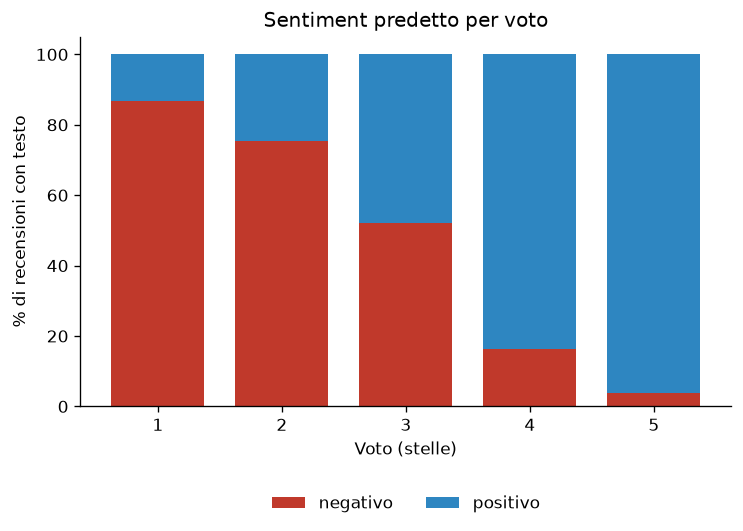

In [51]:
# Grafico 1: quota di recensioni negative e positive per voto. Il modello segue le stelle (87% di negativi al voto 1, 4% al voto 5) e il voto 3 è diviso.
from pathlib import Path
import matplotlib.pyplot as plt

out = Path("outputs"); out.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

ok = reviews_text[reviews_text["sentiment_ok"]]
ct = pd.crosstab(ok["review_score"], ok["sentiment"], normalize="index").mul(100)
ct = ct.reindex(columns=["negative", "positive"]).fillna(0)
ax = ct.plot(kind="bar", stacked=True, color=["#c0392b", "#2e86c1"], figsize=(7, 4), width=0.75)
ax.set_xlabel("Voto (stelle)"); ax.set_ylabel("% di recensioni con testo")
ax.set_title("Sentiment predetto per voto")
ax.legend(["negativo", "positivo"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.xticks(rotation=0)
plt.savefig(out / "01_sentiment_vs_stelle.png", bbox_inches="tight"); plt.show()

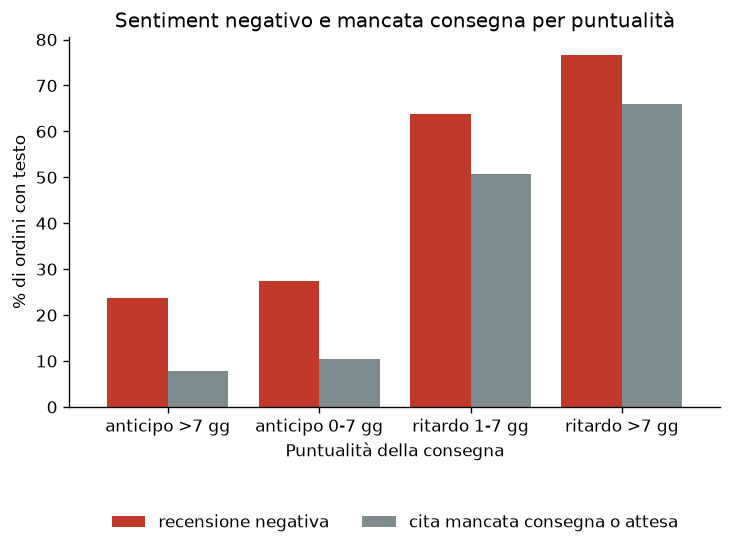

In [52]:
# Grafico 2: negativi e mancata consegna per puntualità. Crescono insieme col ritardo (23,6% → 76,7% e 7,7% → 65,9%).
g = vm.groupby("fascia", observed=True).agg(neg=("neg", "mean"), manc=("cons_mancata", "mean")).mul(100)
ax = g.plot(kind="bar", color=["#c0392b", "#7f8c8d"], figsize=(7, 4), width=0.8)
ax.set_xlabel("Puntualità della consegna"); ax.set_ylabel("% di ordini con testo")
ax.set_title("Sentiment negativo e mancata consegna per puntualità")
ax.legend(["recensione negativa", "cita mancata consegna o attesa"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.xticks(rotation=0)
plt.savefig(out / "02_puntualita.png", bbox_inches="tight"); plt.show()

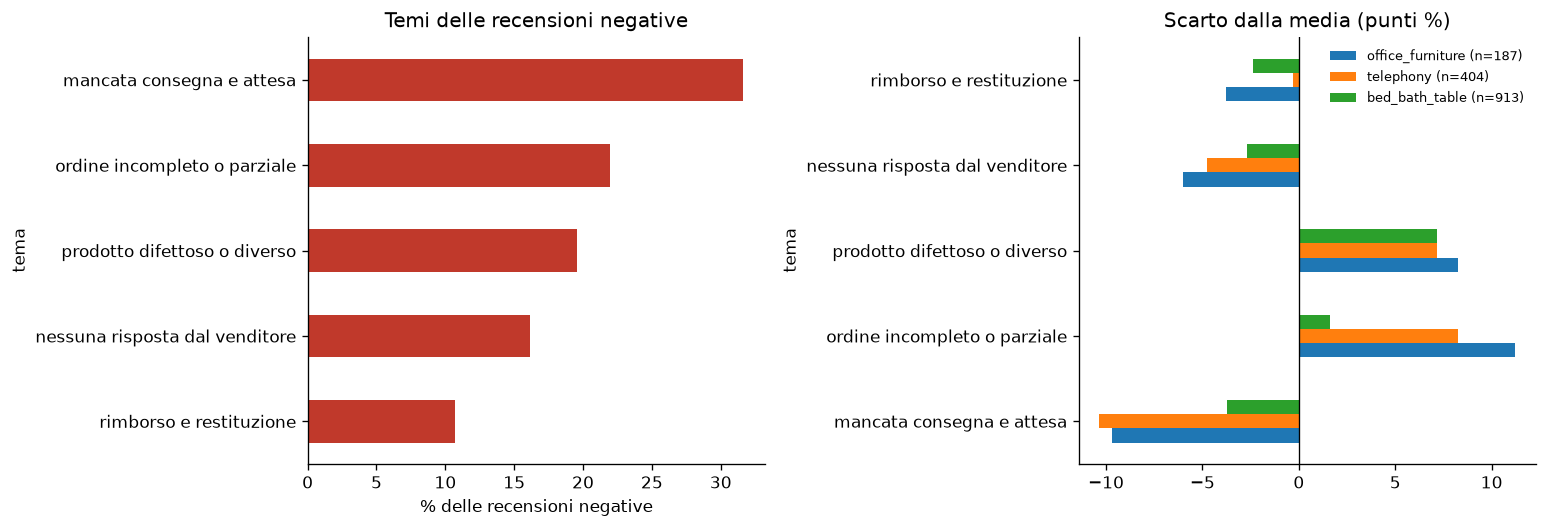

In [53]:
# Grafico 3: a sinistra la quota dei 5 temi, a destra lo scarto dalla media nelle 3 categorie con n sufficiente.
base = rt_neg["tema"].value_counts(normalize=True) * 100
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
base.sort_values().plot(kind="barh", ax=axs[0], color="#c0392b")
axs[0].set_title("Temi delle recensioni negative"); axs[0].set_xlabel("% delle recensioni negative")

rows = {}
for c in ["office_furniture", "telephony", "bed_bath_table"]:
    s = rt_neg.loc[rt_neg["cat"] == c, "tema"].value_counts(normalize=True) * 100
    rows[f"{c} (n={(rt_neg['cat'] == c).sum()})"] = s.reindex(base.index).fillna(0) - base
diff = pd.DataFrame(rows).loc[base.index]
diff.plot(kind="barh", ax=axs[1]); axs[1].axvline(0, color="black", lw=0.8)
axs[1].set_title("Scarto dalla media (punti %)"); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(out / "03_temi_negativi.png", bbox_inches="tight"); plt.show()

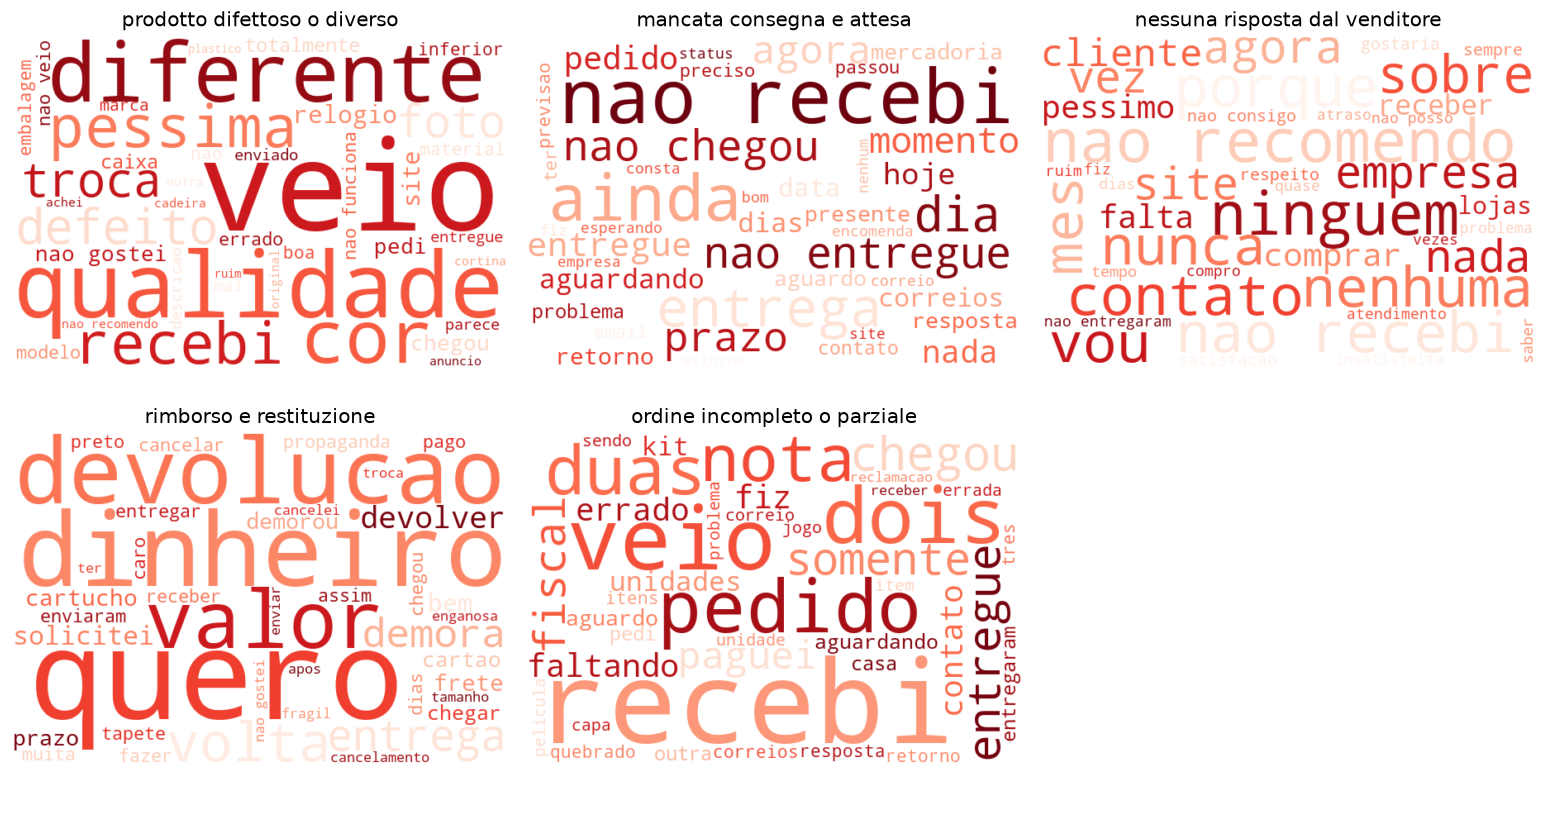

In [54]:
# Grafico 4: parole più pesanti di ogni tema LDA (l'underscore delle negazioni è tolto: nao_recebi → nao recebi).
from wordcloud import WordCloud

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, ax in enumerate(axes.ravel()[:K]):
    freq = {w.replace("_", " "): p for w, p in lda.show_topic(i, topn=40)}
    wc = WordCloud(width=600, height=400, background_color="white", colormap="Reds").generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.set_title(topic_names[i]); ax.axis("off")
for ax in axes.ravel()[K:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(out / "04_wordcloud_temi.png", bbox_inches="tight"); plt.show()